In [1]:
import pandas as pd
import numpy as np
import scipy.stats
import seaborn as sns
import matplotlib.pyplot as plt
import os
from scipy import stats
import math
from statsmodels.stats.multitest import multipletests
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import pdist
from scipy.spatial.distance import squareform

In [2]:
# load all reads poly(A) info
global_reads_polya = pd.read_table('Fig1/global_reads_polya.txt', index_col=[0]) # comes from the concatenation of all *_minimap2_uniq_sort.bed files (only the reads and polya length columns)
global_reads_polya.head()

,reads,polya,compartment,shRNA,replicate
0,00291413-1f7b-4d82-a083-5bc0207960b0,100,cytoplasm,shCTL,Rep 1
1,7c8a3020-b5ed-4afe-a154-f45f4b1616dc,115,cytoplasm,shCTL,Rep 1
2,003295ed-8108-430f-9273-f775177d7d47,76,cytoplasm,shCTL,Rep 1
3,0088a058-ae96-4a95-a8a9-67f181eb4fcb,120,cytoplasm,shCTL,Rep 1
4,00ad06a0-670a-4002-b8b4-5fb3a2a9b6ef,101,cytoplasm,shCTL,Rep 1


C:\Users\bacs5867\AppData\Local\Temp\ipykernel_11300\1705462081.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  global_reads_polya_nonull['condition'] = global_reads_polya_nonull['shRNA'] + ' ' + global_reads_polya_nonull['compartment']


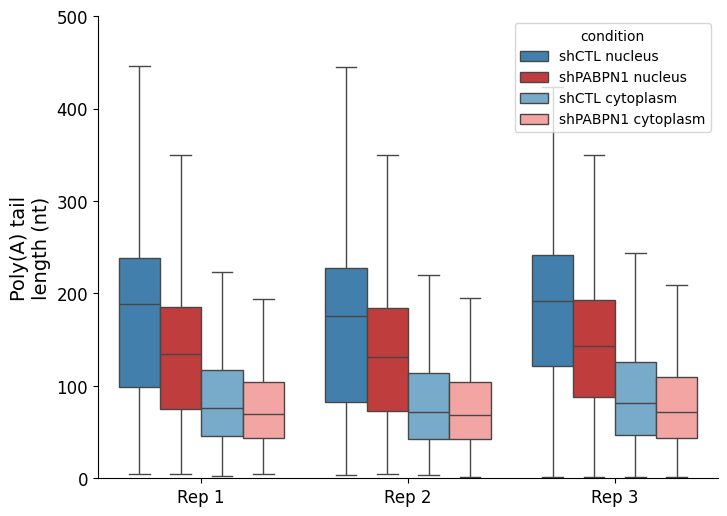

In [3]:
# distribution of poly(A) tail lengths
global_reads_polya_nonull = global_reads_polya[global_reads_polya['polya'] != 0]
global_reads_polya_nonull['condition'] = global_reads_polya_nonull['shRNA'] + ' ' + global_reads_polya_nonull['compartment']

custom_palette = [sns.color_palette('tab20c')[0], sns.color_palette('tab20')[6], sns.color_palette('tab20c')[1], sns.color_palette('tab20')[7]]
fig, axes = plt.subplots(figsize=(8, 6))
sns.boxplot(data = global_reads_polya_nonull, x = 'replicate', hue = 'condition', y = 'polya',
            hue_order = ['shCTL nucleus', 'shPABPN1 nucleus', 'shCTL cytoplasm', 'shPABPN1 cytoplasm'], order=['Rep 1', 'Rep 2', 'Rep 3'], showfliers = False, palette = custom_palette)
plt.ylim(0,500)
plt.xlabel('')
plt.tick_params(labelsize = 12)
plt.ylabel('Poly(A) tail\nlength (nt)', fontsize = 14)
sns.despine()

In [4]:
# stat test
polya_shCTL_nucleus = global_reads_polya_nonull[global_reads_polya_nonull['condition'] == 'shCTL nucleus']['polya'].tolist()
polya_shPABPN1_nucleus = global_reads_polya_nonull[global_reads_polya_nonull['condition'] == 'shPABPN1 nucleus']['polya'].tolist()
polya_shCTL_cyto = global_reads_polya_nonull[global_reads_polya_nonull['condition'] == 'shCTL cytoplasm']['polya'].tolist()
polya_shPABPN1_cyto = global_reads_polya_nonull[global_reads_polya_nonull['condition'] == 'shPABPN1 cytoplasm']['polya'].tolist()

U_nucleus, pvalue_polya_nucleus = stats.mannwhitneyu(x = polya_shCTL_nucleus, y = polya_shPABPN1_nucleus)
U_cyto, pvalue_polya_cyto = stats.mannwhitneyu(x = polya_shCTL_cyto, y = polya_shPABPN1_cyto)

print("Comparison of poly(A) tail lengths between shPABPN1 and shCTL\n")
print("Nucleus - pvalue = " + str(pvalue_polya_nucleus) + '\n')
print("Cytoplasm - pvalue = " + str(pvalue_polya_cyto))


Comparison of poly(A) tail lengths between shPABPN1 and shCTL

Nucleus - pvalue = 0.0

Cytoplasm - pvalue = 0.0


In [6]:
global_genes_polya = pd.read_table('Fig1/global_reads_genes_polya.txt', index_col=[0])
global_genes_polya.head()

,reads,polya_length,ensembl_gene,chrom_gene,start_gene,end_gene,strand_gene,gene_name,compartment,shRNA,replicate
0,00291413-1f7b-4d82-a083-5bc0207960b0,100,ENSG00000100575,14,58408494,58427614,-,TIMM9,cytoplasm,shCTL,Rep 1
1,7c8a3020-b5ed-4afe-a154-f45f4b1616dc,115,ENSG00000198755,6,35468408,35470785,+,RPL10A,cytoplasm,shCTL,Rep 1
2,003295ed-8108-430f-9273-f775177d7d47,76,ENSG00000108518,17,4945652,4949061,-,PFN1,cytoplasm,shCTL,Rep 1
3,0088a058-ae96-4a95-a8a9-67f181eb4fcb,120,ENSG00000104472,8,140511298,140517137,+,CHRAC1,cytoplasm,shCTL,Rep 1
4,00ad06a0-670a-4002-b8b4-5fb3a2a9b6ef,101,ENSG00000007038,16,2817180,2826304,+,PRSS21,cytoplasm,shCTL,Rep 1


In [7]:
def gene_median_polya(compartment, shRNA, replicate) :
    median_df = global_genes_polya[(global_genes_polya['replicate'] == replicate) & 
                                   (global_genes_polya['compartment'] == compartment) & 
                                   (global_genes_polya['shRNA'] == shRNA)].groupby(by = ['gene_name', 'compartment', 'shRNA', 'replicate'])['polya_length'].median().reset_index()
    count_df = global_genes_polya[(global_genes_polya['replicate'] == replicate) & 
                                  (global_genes_polya['compartment'] == compartment) & 
                                  (global_genes_polya['shRNA'] == shRNA)].groupby(by = ['gene_name'])['polya_length'].count().reset_index().rename(columns={'polya_length' : 'count'})
    median_df = median_df.merge(count_df, on = 'gene_name')
    median_df = median_df[median_df['count'] >= 5] # keep only genes covered by at leat 5 reads in 1 rep
    return(median_df)


In [8]:
shCTL_cyto_rep1_median = gene_median_polya('cytoplasm', 'shCTL', 'Rep 1')
shCTL_cyto_rep2_median = gene_median_polya('cytoplasm', 'shCTL', 'Rep 2')
shCTL_cyto_rep3_median = gene_median_polya('cytoplasm', 'shCTL', 'Rep 3')

shCTL_nuc_rep1_median = gene_median_polya('nucleus', 'shCTL', 'Rep 1')
shCTL_nuc_rep2_median = gene_median_polya('nucleus', 'shCTL', 'Rep 2')
shCTL_nuc_rep3_median = gene_median_polya('nucleus', 'shCTL', 'Rep 3')

shPABPN1_cyto_rep1_median = gene_median_polya('cytoplasm', 'shPABPN1', 'Rep 1')
shPABPN1_cyto_rep2_median = gene_median_polya('cytoplasm', 'shPABPN1', 'Rep 2')
shPABPN1_cyto_rep3_median = gene_median_polya('cytoplasm', 'shPABPN1', 'Rep 3')

shPABPN1_nuc_rep1_median = gene_median_polya('nucleus', 'shPABPN1', 'Rep 1')
shPABPN1_nuc_rep2_median = gene_median_polya('nucleus', 'shPABPN1', 'Rep 2')
shPABPN1_nuc_rep3_median = gene_median_polya('nucleus', 'shPABPN1', 'Rep 3')

shCTL_cyto_rep1_median

,gene_name,compartment,shRNA,replicate,polya_length,count
0,7SK,cytoplasm,shCTL,Rep 1,19.0,7
4,AAAS,cytoplasm,shCTL,Rep 1,76.0,121
5,AACS,cytoplasm,shCTL,Rep 1,79.0,51
6,AAGAB,cytoplasm,shCTL,Rep 1,72.0,56
7,AAK1,cytoplasm,shCTL,Rep 1,78.0,9
...,...,...,...,...,...,...
12468,ZYG11A,cytoplasm,shCTL,Rep 1,130.0,6
12469,ZYG11B,cytoplasm,shCTL,Rep 1,49.5,20
12470,ZYX,cytoplasm,shCTL,Rep 1,82.5,140
12471,ZZEF1,cytoplasm,shCTL,Rep 1,77.0,6


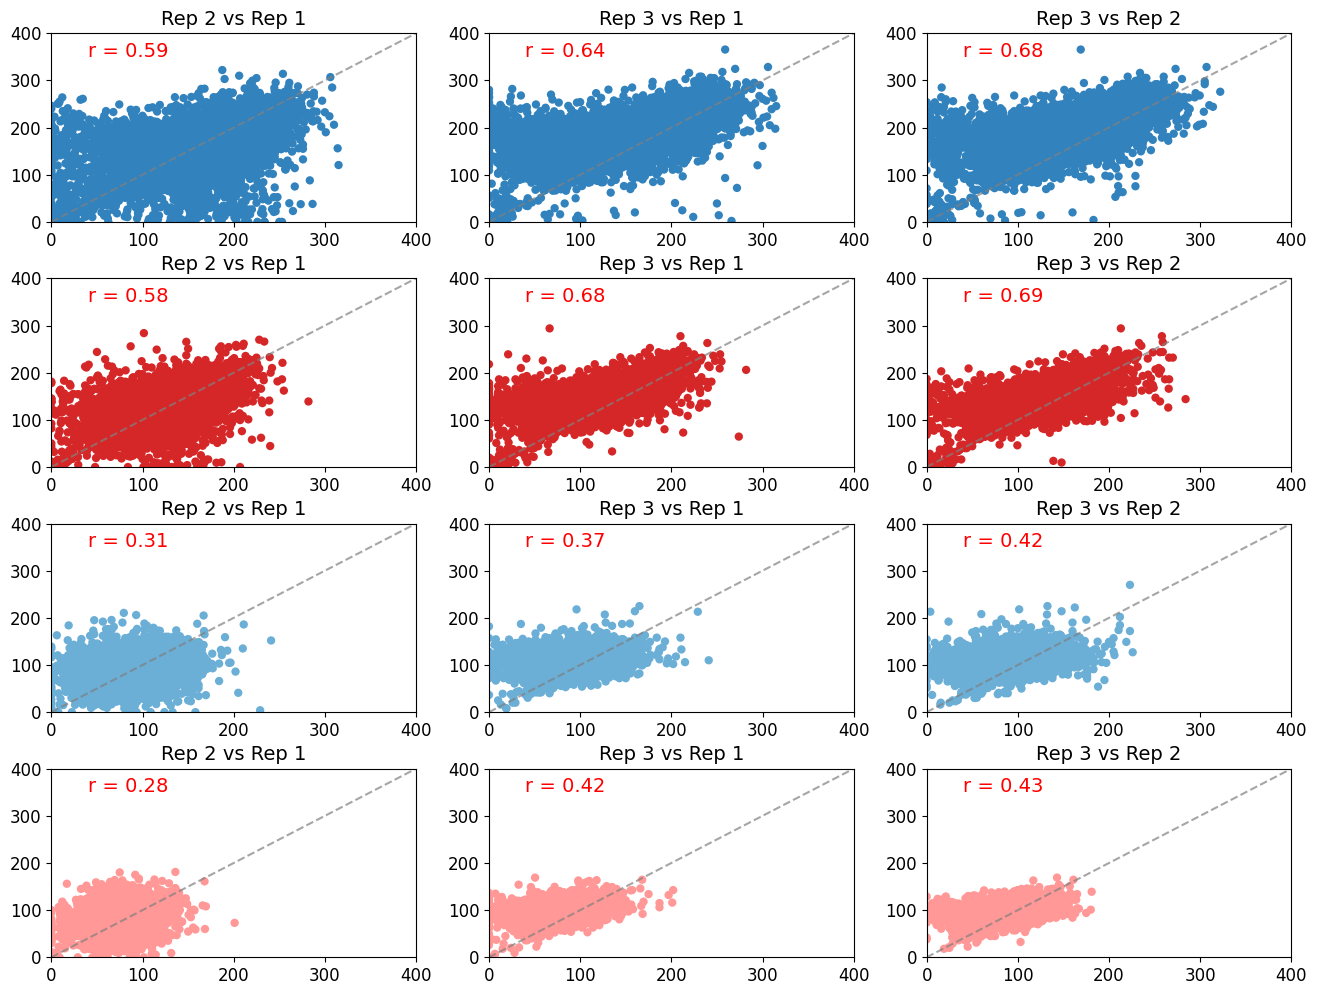

In [9]:
# correlation of median poly(A) tail lengths
shCTL_cyto_list_df = [shCTL_cyto_rep1_median, shCTL_cyto_rep2_median, shCTL_cyto_rep3_median]
shCTL_nuc_list_df = [shCTL_nuc_rep1_median, shCTL_nuc_rep2_median, shCTL_nuc_rep3_median]
shPABPN1_cyto_list_df = [shPABPN1_cyto_rep1_median, shPABPN1_cyto_rep2_median, shPABPN1_cyto_rep3_median]
shPABPN1_nuc_list_df = [shPABPN1_nuc_rep1_median, shPABPN1_nuc_rep2_median, shPABPN1_nuc_rep3_median]

custom_palette = [sns.color_palette('tab20c')[0], sns.color_palette('tab20')[6], sns.color_palette('tab20c')[1], sns.color_palette('tab20')[7]]
fig, axes = plt.subplots(4, 3, figsize=(16, 12))
list_all_df = [shCTL_nuc_list_df, shPABPN1_nuc_list_df, shCTL_cyto_list_df, shPABPN1_cyto_list_df]
list_titles = ['Rep 2 vs Rep 1', 'Rep 3 vs Rep 1', 'Rep 3 vs Rep 2']
for i in range(4) :
    df_list = list_all_df[i]
    merge_df_rep1_rep2 = df_list[0].merge(df_list[1], on = 'gene_name')
    merge_df_rep1_rep3 = df_list[0].merge(df_list[2], on = 'gene_name')
    merge_df_rep2_rep3 = df_list[1].merge(df_list[2], on = 'gene_name')
    list_merge = [merge_df_rep1_rep2, merge_df_rep1_rep3, merge_df_rep2_rep3]
    for j in range(3) :
        merge_df = list_merge[j]
        xlist = merge_df['polya_length_x'].tolist()
        ylist = merge_df['polya_length_y'].tolist()
        pvalue = stats.pearsonr(x=xlist, y=ylist)[0]
        sns.scatterplot(data = merge_df, x = 'polya_length_x', y = 'polya_length_y', ax = axes[i, j], edgecolor = 'none', color = custom_palette[i], rasterized = True)
        axes[i, j].set_xlim(0, 400)
        axes[i, j].set_ylim(0, 400)
        axes[i, j].text(x=40, y=350, s='r = ' + str(pvalue.round(2)), fontsize=14, color='red')
        axes[i, j].set_xlabel('')
        axes[i, j].set_ylabel('')
        axes[i, j].plot((0, 400), (0, 400), color='grey', linestyle='--', alpha=0.7)
        axes[i, j].set_title(list_titles[j], fontsize = 14)
        axes[i, j].tick_params(labelsize = 12)
plt.subplots_adjust(hspace = 0.3)

In [10]:
# generate data for volcano plots
def genes_polya_stat_test(compartment) :
    shCTL_genes_polya_list = global_genes_polya[(global_genes_polya['compartment'] == compartment) & (global_genes_polya['shRNA'] == 'shCTL')].groupby(by = 'gene_name')['polya_length'].apply(list).reset_index()
    shCTL_genes_polya_list['coverage'] = shCTL_genes_polya_list.apply(lambda row: len(row.polya_length), axis = 1)
    shCTL_genes_polya_list = shCTL_genes_polya_list[shCTL_genes_polya_list['coverage'] >= 20] # keep genes with >= 20 reads in 3 reps combined

    shPABPN1_genes_polya_list = global_genes_polya[(global_genes_polya['compartment'] == compartment) & (global_genes_polya['shRNA'] == 'shPABPN1')].groupby(by = 'gene_name')['polya_length'].apply(list).reset_index()
    shPABPN1_genes_polya_list['coverage'] = shPABPN1_genes_polya_list.apply(lambda row: len(row.polya_length), axis = 1)
    shPABPN1_genes_polya_list = shPABPN1_genes_polya_list[shPABPN1_genes_polya_list['coverage'] >= 20] # keep genes with >= 20 reads in 3 reps combined

    genes_polya_list_merge = shCTL_genes_polya_list.merge(shPABPN1_genes_polya_list, on = 'gene_name')
    genes_polya_list_merge.columns = ['gene_name', 'polya_length_ctl', 'coverage_ctl', 'polya_length_pab', 'coverage_pab']

    genes_polya_list_merge['median_polya_length_ctl'] = genes_polya_list_merge.apply(lambda row : np.median(row.polya_length_ctl), axis = 1)
    genes_polya_list_merge['median_polya_length_pab'] = genes_polya_list_merge.apply(lambda row : np.median(row.polya_length_pab), axis = 1)
    genes_polya_list_merge['FC'] = genes_polya_list_merge['median_polya_length_pab'] / genes_polya_list_merge['median_polya_length_ctl']
    genes_polya_list_merge = genes_polya_list_merge[genes_polya_list_merge['FC'] != 0]
    genes_polya_list_merge['log2FoldChange'] = genes_polya_list_merge.apply(lambda row : math.log2(row.FC), axis = 1)

    genes_polya_list_merge['pvalue'] = genes_polya_list_merge.apply(lambda row : stats.mannwhitneyu(row.polya_length_pab, row.polya_length_ctl)[1], axis = 1)
    genes_polya_list_merge['FDR'] = multipletests(genes_polya_list_merge['pvalue'].astype(float), alpha=0.05, method='fdr_bh')[1]

    genes_polya_list_merge['effect on polyA tail'] = 'not significant'
    genes_polya_list_merge.loc[(genes_polya_list_merge['FDR'] <= 0.05) & (genes_polya_list_merge['log2FoldChange'] >= 0), 'effect on polyA tail'] = 'polyA tail lengthening'
    genes_polya_list_merge.loc[(genes_polya_list_merge['FDR'] <= 0.05) & (genes_polya_list_merge['log2FoldChange'] <= 0), 'effect on polyA tail'] = 'polyA tail shortening'
    genes_polya_list_merge = genes_polya_list_merge.sort_values(by = 'FDR')

    return(genes_polya_list_merge)


In [11]:
cyto_genes_polya_compare = genes_polya_stat_test('cytoplasm')
nuc_genes_polya_compare = genes_polya_stat_test('nucleus')

cyto_genes_polya_compare = cyto_genes_polya_compare.drop(columns = ['polya_length_ctl', 'polya_length_pab'])
nuc_genes_polya_compare = nuc_genes_polya_compare.drop(columns = ['polya_length_ctl', 'polya_length_pab'])

# export data for volcano plots - plotted with R
cyto_genes_polya_compare.to_csv('Fig1/cyto_genes_polya_compare.txt', sep = '\t')
nuc_genes_polya_compare.to_csv('Fig1/nuc_genes_polya_compare.txt', sep = '\t')

C:\Users\bacs5867\AppData\Local\Temp\ipykernel_11300\1644279481.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  global_genes_polya_subset['condition'] = global_genes_polya_subset['shRNA'] + ' ' + global_genes_polya_subset['compartment']


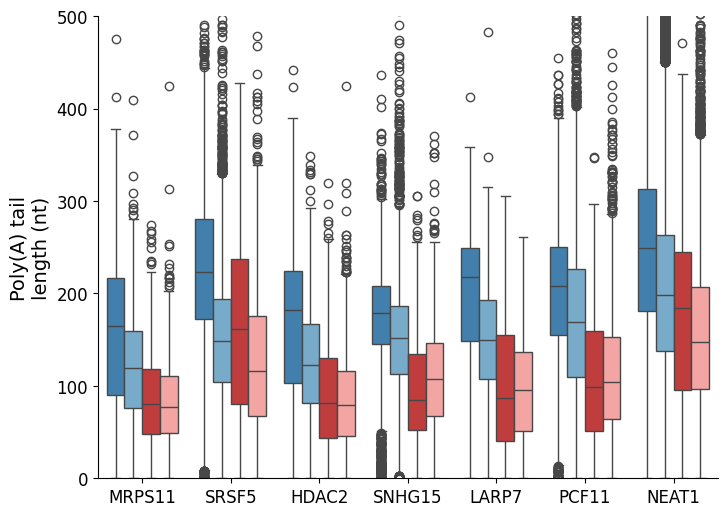

In [12]:
# distribution of poly(A) tail lengths for example genes
example_genes = ['NEAT1', 'MRPS11', 'SNHG15', 'SPATA5L1', 'HDAC2', 'SRSF5', 'PCF11', 'LARP7']
global_genes_polya_subset = global_genes_polya[global_genes_polya['gene_name'].isin(example_genes)]
global_genes_polya_subset['condition'] = global_genes_polya_subset['shRNA'] + ' ' + global_genes_polya_subset['compartment']

custom_palette = [sns.color_palette('tab20c')[0], sns.color_palette('tab20c')[1], sns.color_palette('tab20')[6], sns.color_palette('tab20')[7]]
fig, axes = plt.subplots(figsize=(8, 6))
sns.boxplot(data = global_genes_polya_subset, x = 'gene_name', y = 'polya_length', hue = 'condition', hue_order=['shCTL nucleus', 'shPABPN1 nucleus', 'shCTL cytoplasm', 'shPABPN1 cytoplasm'], palette = custom_palette)
plt.legend('', frameon = False)
plt.ylabel('Poly(A) tail\nlength (nt)', fontsize = 14)
plt.xlabel('')
plt.ylim(0,500)
plt.tick_params(labelsize = 12)
sns.despine()

# Hierarchical clustering

In [13]:
# import global poly(A) reads data without external gene name
global_reads_genes_polya = pd.read_table('Fig1/global_reads_genes_polya_without_gene_name.txt', index_col=[0])
global_genes_polya_no_null = global_reads_genes_polya[global_reads_genes_polya['polya_length'] != 0]
global_reads_genes_polya.head()

,reads,polya_length,ensembl_gene,condition
0,00291413-1f7b-4d82-a083-5bc0207960b0,100,ENSG00000100575,shCTL cytoplasm
1,7c8a3020-b5ed-4afe-a154-f45f4b1616dc,115,ENSG00000198755,shCTL cytoplasm
2,003295ed-8108-430f-9273-f775177d7d47,76,ENSG00000108518,shCTL cytoplasm
3,0088a058-ae96-4a95-a8a9-67f181eb4fcb,120,ENSG00000104472,shCTL cytoplasm
4,00ad06a0-670a-4002-b8b4-5fb3a2a9b6ef,101,ENSG00000007038,shCTL cytoplasm


In [14]:
genes_count = global_genes_polya_no_null.groupby(['ensembl_gene', 'condition'])['polya_length'].count().reset_index()
genes_count = genes_count.rename(columns = {'polya_length':'count'})
genes_count = genes_count[genes_count['count'] >= 20] # keep only genes with 20 reads in each condition
genes_polya = global_genes_polya_no_null.groupby(['ensembl_gene', 'condition'])['polya_length'].median().reset_index()
genes_polya = genes_polya.merge(genes_count, on = ['ensembl_gene', 'condition'])
genes_polya = genes_polya.pivot_table(index = ['ensembl_gene'], columns=['condition'], values=['polya_length']).reset_index()
genes_polya.columns = ['ensembl_gene', 'shCTL cytoplasm', 'shCTL nucleus', 'shPABPN1 cytoplasm', 'shPABPN1 nucleus']
genes_polya = genes_polya.dropna().set_index('ensembl_gene') # keep only genes detected in all conditions

genes_polya.head()

,shCTL cytoplasm,shCTL nucleus,shPABPN1 cytoplasm,shPABPN1 nucleus
ensembl_gene,,,,
ENSG00000000003,87.0,144.0,85.0,138.0
ENSG00000000419,89.0,216.0,82.0,160.0
ENSG00000000457,106.0,210.0,85.0,130.0
ENSG00000000460,80.5,220.0,84.5,174.5
ENSG00000001036,88.5,164.0,84.0,123.0


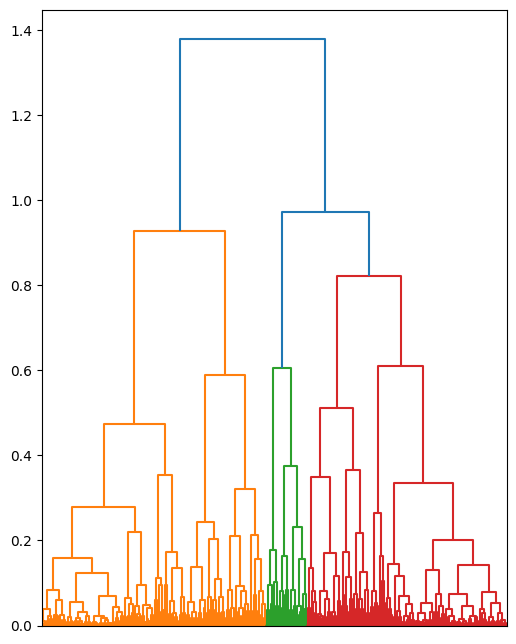

In [15]:
scaled_data = StandardScaler().fit_transform(genes_polya)

# correlation distance
dist = pdist(scaled_data, metric="correlation")
# clustering
Z = linkage(dist, method="average")
# plot dendrogram
plt.figure(figsize=(6, 8))
dendrogram(Z, no_labels=True)
plt.show()

In [16]:
cluster_labels = scipy.cluster.hierarchy.cut_tree(Z, n_clusters=5).reshape(-1, ) # chose number of clusters from graph
genes_polya['cluster'] = cluster_labels
genes_polya['cluster'] = genes_polya['cluster'] + 1
genes_polya = genes_polya.reset_index()

cluster_count = genes_polya.groupby(by = 'cluster')['ensembl_gene'].count()
cluster_count

cluster
1    1544
2    3585
3    2007
4    3404
5    1018
Name: ensembl_gene, dtype: int64

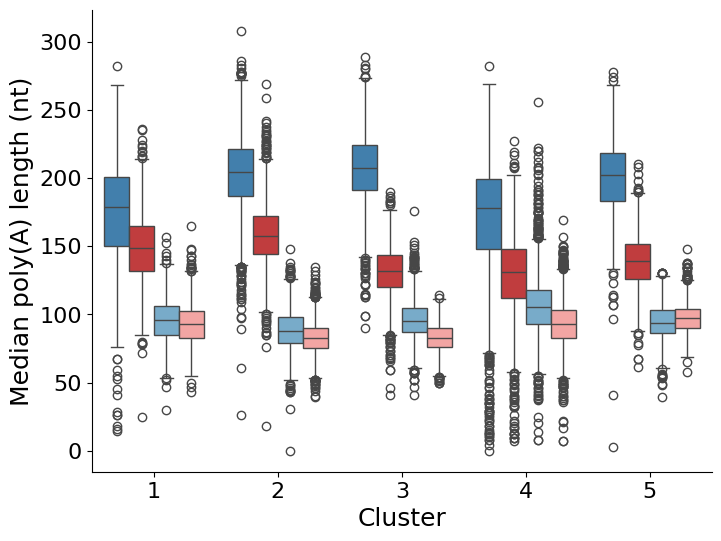

In [17]:
# distribution of poly(A) tail lengths across clusters
genes_polya_data = global_reads_genes_polya.groupby(['ensembl_gene', 'condition'])['polya_length'].median().reset_index()
genes_polya_data = genes_polya_data.merge(genes_polya[['ensembl_gene', 'cluster']].drop_duplicates(), on = 'ensembl_gene')

custom_palette = [sns.color_palette('tab20c')[0], sns.color_palette('tab20')[6], sns.color_palette('tab20c')[1], sns.color_palette('tab20')[7]]
fig, axes = plt.subplots(figsize=(8, 6))
sns.boxplot(data = genes_polya_data, y = 'polya_length', x = 'cluster', hue = 'condition', hue_order=['shCTL nucleus', 'shPABPN1 nucleus', 'shCTL cytoplasm', 'shPABPN1 cytoplasm'], palette=custom_palette)
#plt.title('Hierarchical clustering', fontsize = 16)
plt.ylabel('Median poly(A) length (nt)', fontsize = 18)
plt.xlabel('Cluster', fontsize = 18)
plt.tick_params(labelsize = 16)
plt.legend('', frameon = False)
sns.despine()

In [18]:
# export data for GO analysis - with R
genes_polya = genes_polya.rename(columns = {'gene_name' : 'Geneid'})
genes_polya.to_csv('Fig1/genes_polya_median_clusters.txt', sep = '\t')
